# Visualize results by experiment

The plots are based on our initial design for Experiment 1–4:
[Experiment Design](https://docs.google.com/spreadsheets/d/1_5904_TopKtOvUDnBJP0cXXRUClkqbCAXoJN4WBs3fc/edit?gid=924700404#gid=924700404)

All figures save to `ROOT_FOLDER/plots`. PNG is the default; enable `save_pdf` in an individual plot's configuration for PDF.

Dependencies: m4opt env
```
python -m pip install m4opt
```

## Shared setup

Set the root folder that contains experiment result folder `exp1`, `exp2`, `exp3` and `exp4`. 

In [1]:
from pathlib import Path

ROOT_FOLDER = Path('/Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results')

In [2]:
import math
import re
from collections import defaultdict
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogFormatterMathtext, LogLocator, MaxNLocator, NullFormatter
import numpy as np
from astropy import units as u
from astropy.table import QTable
from scipy.stats import bootstrap

PROBLEMS = ['p1', 'p2']
MISSIONS = ['uvex', 'ultrasat', 'ztf', 'rubin']
ALGORITHMS = ['m4opt_milp', 'greedy_marginal', 'greedy_ratio', 'gcp', 'simulated_annealing', 'ilp_continuous']
TIME_COLUMN = 'planning_time_seconds'
EXP3_REQUIRE_COMPLETE_RUNS = True  # Require valid values for every available run.
BAR_GROUP_WIDTH = 0.84
BOUND_INFINITY_CUTOFF = 1000000000000000.0
BOUND_TOLERANCE = 1e-08
FAILED_RUN_PROBABILITY = 0.0
REQUIRE_ALL_EVENTS = True
BOOTSTRAP_SAMPLES = 10000
RANDOM_SEED = 0
DISPLAY_PLOTS = True
# Fixed experiment and analysis settings.
PLOT_DEFAULTS = {'enabled': True,
 'result_pattern': '*.ecsv',
 'require_all_events': True,
 'failed_run_probability': 0.0,
 'bootstrap_samples': 10000,
 'random_seed': 0,
 'figure_overrides': {}}
_FIXED_PLOT_SETTINGS = {'exp1_probability': {'experiment': 'exp1',
                      'kind': 'events',
                      'metric': 'probability_percent',
                      'input_folder': '.',
                      'include_bounds': False,
                      'log_time': True,
                      'band_alpha': 0.13},
 'exp1_time': {'experiment': 'exp1',
               'kind': 'events',
               'metric': 'planning_time_seconds',
               'input_folder': '.',
               'include_bounds': False,
               'bar_probability': True,
               'band_alpha': 0.13},
 'exp2_events_probability': {'experiment': 'exp2',
                             'kind': 'events',
                             'metric': 'probability_percent',
                             'input_folder': '.',
                             'include_bounds': False,
                             'bar_probability': True,
                             'log_time': True,
                             'band_alpha': 0.13},
 'exp2_events_time': {'experiment': 'exp2',
                      'kind': 'events',
                      'metric': 'planning_time_seconds',
                      'input_folder': '.',
                      'include_bounds': False,
                      'bar_probability': True,
                      'band_alpha': 0.13},
 'exp2_mean_probability': {'experiment': 'exp2',
                           'kind': 'means',
                           'metric': 'probability_percent',
                           'input_folder': '.',
                           'event_label_mode': 'index',
                           'log_time': True},
 'exp2_mean_time': {'experiment': 'exp2',
                    'kind': 'means',
                    'metric': 'planning_time_seconds',
                    'input_folder': '.',
                    'event_label_mode': 'index'},
 'exp3_time': {'experiment': 'exp3',
               'kind': 'exp3',
               'metric': 'planning_time_seconds',
               'stage': 'original',
               'original_folder': 'original_deadline',
               'adjusted_folder': 'adjusted_deadline',
               'require_complete_runs': True,
               'reserve_time_column': 'planning_time_seconds',
               'event_label_mode': 'index',
               'panel_fontsize': 7},
 'exp3_probability': {'experiment': 'exp3',
                      'kind': 'exp3',
                      'metric': 'probability_percent',
                      'stage': 'original',
                      'original_folder': 'original_deadline',
                      'adjusted_folder': 'adjusted_deadline',
                      'require_complete_runs': True,
                      'reserve_time_column': 'planning_time_seconds',
                      'event_label_mode': 'index',
                      'panel_fontsize': 7,
                      'log_time': True},
 'exp3_adjusted_probability': {'experiment': 'exp3',
                               'kind': 'exp3',
                               'metric': 'probability_percent',
                               'stage': 'final',
                               'original_folder': 'original_deadline',
                               'adjusted_folder': 'adjusted_deadline',
                               'require_complete_runs': True,
                               'reserve_time_column': 'planning_time_seconds',
                               'event_label_mode': 'index',
                               'panel_fontsize': 7,
                               'log_time': True},
 'exp4_wcet': {'experiment': 'exp4',
               'kind': 'wcet',
               'metric': 'planning_time_seconds',
               'input_folder': 'original_deadline',
               'event_label_mode': 'index',
               'panel_fontsize': 7,
               'band_alpha': 0.13},
 'exp4_probability': {'experiment': 'exp4',
                      'kind': 'means',
                      'metric': 'probability_percent',
                      'input_folder': 'adjusted_deadline',
                      'event_label_mode': 'index',
                      'panel_fontsize': 7,
                      'log_time': True},
 'exp4_time': {'experiment': 'exp4',
               'kind': 'means',
               'metric': 'planning_time_seconds',
               'input_folder': 'adjusted_deadline',
               'event_label_mode': 'index',
               'panel_fontsize': 7}}
# Combined view uses the same inputs and validation as adjusted probability.
_FIXED_PLOT_SETTINGS["exp3_combined"] = dict(
    _FIXED_PLOT_SETTINGS["exp3_adjusted_probability"], kind="exp3_combined")
PLOT_CONFIG = {}
FIGURE_OVERRIDES = {}

LABELS = {
    "m4opt_milp": "M4OPT-MILP",
    "greedy_marginal": "Greedy-Marginal",
    "greedy_ratio": "Greedy-Ratio",
    "gcp": "SGCP",
    "simulated_annealing": "SA",
    "genetic": "GA",
    "ant_colony": "ACO",
    "rg_qp": "RG-QP",
    "ilp_continuous": "SO-MILP",
    "ilp_mtz": "MTZ-MILP",
}
ALIASES = {"m4opt": "m4opt_milp", "milp": "m4opt_milp", "sa": "simulated_annealing",
           "ga": "genetic", "aco": "ant_colony", "ilp_continuous_time": "ilp_continuous"}

COLORS = {
    "m4opt_milp": "#222222", "greedy_marginal": "#0072B2",
    "greedy_ratio": "#E69F00", "gcp": "#009E73",
    "simulated_annealing": "#D55E00", "ilp_continuous": "#CC79A7",
    "ilp_mtz": "#56B4E9", "genetic": "#8C6D31",
    "ant_colony": "#666666", "rg_qp": "#882255",
}
MARKERS = {"m4opt_milp": "P", "greedy_marginal": "o", "greedy_ratio": "s",
           "gcp": "^", "simulated_annealing": "v", "ilp_continuous": "D",
           "ilp_mtz": "X", "genetic": "*", "ant_colony": "<", "rg_qp": ">"}

LINESTYLES = {"m4opt_milp": "-", "greedy_marginal": ":", "greedy_ratio": ":",
              "gcp": "-", "simulated_annealing": "--", "ilp_continuous": "--",
              "ilp_mtz": "-.", "genetic": ":", "ant_colony": "--", "rg_qp": "-."}
STYLES = {name: dict(color=COLORS[name], marker=MARKERS[name], linestyle=LINESTYLES[name],
                    linewidth=1.1, markersize=3.2, markeredgewidth=0.6) for name in COLORS}
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
})

METRIC_LABELS = {
    "probability_percent": "Collected probability (%)",
    "planning_time_seconds": "Planning latency (s)",
    "solver_call_time_seconds": "Solver-call time (s)",
    "solution_time_seconds": "Solution time (s)",
    "best_bound_percent": "Collected probability upper bound (%)",
    "relative_gap_percent": "Relative optimality gap (%)",
}
DEADLINE_LABELS = {
    "exp1": r"Execution budget $D_{\mathrm{exec}}$ (min)",
    "exp2": r"Execution budget $D_{\mathrm{exec}}$ (min)",
    "exp3": r"Execution budget $D_{\mathrm{exec}}$ (min)",
    "exp4": r"Response deadline $D$ (min)",
}
PROBLEM_STYLES = {
    "p1": dict(color="#0072B2", marker="o", linestyle="-", linewidth=1.1, markersize=3.2),
    "p2": dict(color="#D55E00", marker="s", linestyle="--", linewidth=1.1, markersize=3.2),
}
_SAVED_PLOT_PATHS = set()  # Reset by main(); prevent different figures overwriting each other.


def number(value, unit=None):
    """Convert a scalar or quantity; unavailable values remain NaN."""
    try:
        return float(u.Quantity(value, unit).value if unit else getattr(value, "value", value))
    except (TypeError, ValueError, OverflowError):
        return math.nan


def read_result(path):
    table = QTable.read(path, format="ascii.ecsv")
    meta = dict(table.meta.get("args") or {})
    meta.update({key: value for key, value in table.meta.items() if value is not None})

    # Metadata takes priority; filenames supply fields missing from older ECSV files.
    problem = re.search(r"(?:^|_)(p[12])(?:_|$)", path.stem, re.I)
    mission = re.search(r"(?:^|_)(uvex|ultrasat|ztf|rubin)(?:_|$)", path.stem, re.I)
    cap = re.search(r"_n(\d+)(?:_|$)", path.stem, re.I)
    deadline = re.search(r"_deadline(.+?)(?:_(\d+))?(?:_(final))?$", path.stem, re.I)
    run = deadline[2] if deadline and deadline[2] else ("final" if path.stem.lower().endswith("_final") else "")
    if isinstance(meta.get("wcet_run"), dict) and "run" in meta["wcet_run"]:
        run = str(meta["wcet_run"]["run"])
    algorithm = next((name for name in sorted(set(LABELS) | set(ALIASES) | set(ALGORITHMS),
                                             key=len, reverse=True)
                      if re.search(r"_" + re.escape(name) + r"(?:_|$)", path.stem, re.I)),
                     "m4opt_milp")
    algorithm = str(meta.get("cpp_algorithm") or meta.get("algorithm") or algorithm)
    algorithm = algorithm.strip().lower().replace("-", "_").replace(" ", "_")
    map_name = str(meta.get("skymap") or "").replace("\\", "/").rsplit("/", 1)[-1]
    if not map_name:
        map_name = re.sub(r"^p[12]_[^_]+_", "", path.stem, flags=re.I)
        map_name = re.split(r"_(?:" + "|".join(map(re.escape, LABELS | ALIASES)) + r")(?:_|$)",
                            map_name, maxsplit=1, flags=re.I)[0]
    event = re.search(r"GW\d{6}_\d{6}", map_name, re.I)
    map_name = event[0].upper() if event else re.sub(r"\.(fits|fit|fts)(\.gz)?$", "", map_name, flags=re.I)
    deadline_value = meta.get("deadline")
    if deadline_value is None:
        deadline_value = deadline[1].replace("_", " ") if deadline else next(
            (p.name[9:].replace("_", " ") for p in path.parents if p.name.startswith("deadline_")), None)
    deadline_seconds = number(deadline_value, u.s)
    # Compare final reruns by original deadline; retain reduced deadlines for validation.
    comparison_deadline = number(meta.get("original_deadline_seconds", deadline_seconds), u.s)
    if not math.isfinite(comparison_deadline):
        raise ValueError("missing or invalid observation deadline")

    probability = number(meta.get("objective_value"))
    if math.isnan(probability):
        probability = number(meta.get("coverage"))
    observations = sum(str(a).lower() == "observe" for a in table["action"]) if "action" in table.colnames else len(table)
    status = str(meta.get("solution_status") or "unknown")
    has_solution = (observations > 0 or "optimal" in status.lower()) and not any(
        text in status.lower() for text in ("infeasible", "no feasible", "no solution", "no incumbent"))
    bound = number(meta.get("best_bound"))
    if math.isnan(bound):
        bound_status = "missing"
    elif not math.isfinite(bound):
        bound_status = "nonfinite"
    elif bound < 0:
        bound_status = "negative"
    elif bound >= BOUND_INFINITY_CUTOFF:
        bound_status = "uninformative"
    elif math.isfinite(probability) and bound < probability - BOUND_TOLERANCE:
        bound_status = "below_objective"
    else:
        bound_status = "reported"
    gap = max(0.0, bound - probability) if (has_solution and bound_status == "reported"
                                             and math.isfinite(probability) and probability >= 0) else math.nan
    relative_gap = 100 * gap / probability if probability > 0 else (0.0 if gap == 0 else math.nan)
    return {
        "map": map_name,
        "problem": str(meta.get("problem") or (problem[1] if problem else "unknown")).lower(),
        "mission": str(meta.get("mission") or (mission[1] if mission else next(
            (p.name for p in path.parents if p.name in MISSIONS), "unknown"))).lower(),
        "algorithm": ALIASES.get(algorithm, algorithm),
        "max_fields": str(meta.get("max_fields", cap[1] if cap else "unknown")),
        "run": run,
        "stage": "final" if path.stem.lower().endswith("_final") else "original",
        "deadline_seconds": deadline_seconds,
        "comparison_deadline_seconds": comparison_deadline,
        "original_deadline_seconds": number(meta.get("original_deadline_seconds"), u.s),
        "adjusted_deadline_seconds": number(meta.get("adjusted_deadline_seconds"), u.s),
        "reserved_wcet_seconds": number(meta.get("wcet_seconds"), u.s),
        "wcet_time_column": str(meta.get("wcet_time_column") or ""),
        "rerun_status": str(meta.get("rerun_status") or ""),
        "status": status,
        "num_observations": observations,
        "confirmed_incumbent": has_solution,
        "probability": probability,
        "probability_percent": probability * 100,
        "planning_time_seconds": number(meta.get("planning_time", meta.get("planning_time_seconds")), u.s),
        "solution_time_seconds": number(meta.get("solution_time", meta.get("solution_time_seconds")), u.s),
        "solver_call_time_seconds": number(meta.get("solver_call_time", meta.get("solver_call_time_seconds")), u.s),
        "best_bound": bound,
        "best_bound_percent": bound * 100,
        "bound_status": bound_status,
        "absolute_gap": gap,
        "relative_gap_percent": relative_gap,
        "result_file": str(path),
    }


def load_results(folder, pattern="*.ecsv", allow_empty=False):
    """Read the selected results once, retaining their event names."""
    if not folder.is_dir():
        raise RuntimeError(f"Result folder does not exist: {folder}")
    rows = []
    for path in sorted(folder.rglob(pattern)):
        if path.name == "wcet.ecsv":
            continue  # Aggregate runner summary, not an individual schedule.
        try:
            row = read_result(path)
        except Exception as error:
            print(f"Warning: could not read {path.name}: {error}")
            continue
        if row["algorithm"] in LABELS:
            rows.append(row)
    if not rows and not allow_empty:
        raise RuntimeError("No readable results match the settings")
    return rows


def event_labels(events, options):
    """Use one ordered map list for all panels in the same figure."""
    if options["event_label_mode"] == "names":
        return list(events), "Events"
    if options["event_label_mode"] != "index":
        raise ValueError('event_label_mode must be "names" or "index"')
    labels = ([chr(65 + i) for i in range(len(events))] if len(events) <= 26
              else [str(i + 1) for i in range(len(events))])
    return labels, "Events"


def metric_values(rows, metric):
    """Valid repeat values grouped by map; timing remains valid for failed runs."""
    values = defaultdict(list)
    for row in rows:
        value = row[metric]
        if metric == "probability_percent" and not row["confirmed_incumbent"]:
            value = (0.0 if row.get("rerun_status") == "not_run_no_observing_budget"
                     else number(FAILED_RUN_PROBABILITY) * 100)
        if metric.startswith("best_bound") and row["bound_status"] != "reported":
            continue
        if math.isfinite(value) and value >= 0:
            values[row["map"]].append(value)
    return values


def mean_ci(values):
    values = np.asarray(values, dtype=float)
    if not len(values):
        return math.nan, math.nan, math.nan
    mean = float(np.mean(values))
    if len(values) == 1:
        return mean, math.nan, math.nan
    if np.all(values == values[0]):
        return mean, mean, mean
    interval = bootstrap((values,), np.mean, method="BCa", confidence_level=0.95,
                         n_resamples=BOOTSTRAP_SAMPLES,
                         random_state=np.random.default_rng(RANDOM_SEED)).confidence_interval
    return mean, float(interval.low), float(interval.high)


def get_plot_options(plot_id, mission=None, problem=None):
    """Resolve defaults, one plot's settings, and an optional individual-figure override."""
    options = {**PLOT_DEFAULTS, **_FIXED_PLOT_SETTINGS[plot_id], **PLOT_CONFIG[plot_id],
               **FIGURE_OVERRIDES.get((plot_id, mission, problem), {})}
    algorithms = options["algorithms"]
    if algorithms is not None:
        if not isinstance(algorithms, list) or not all(isinstance(a, str) for a in algorithms):
            raise ValueError(f"{plot_id}: algorithms must be a list of IDs or None")
        algorithms = [ALIASES.get(a, a) for a in algorithms]
        if len(set(algorithms)) != len(algorithms) or not set(algorithms) <= LABELS.keys():
            raise ValueError(f"{plot_id}: choose distinct algorithms from {list(LABELS)}")
        options["algorithms"] = algorithms
    options["problems"], options["missions"] = list(options["problems"]), list(options["missions"])
    if not options["problems"] or len(set(options["problems"])) != len(options["problems"]) or not set(options["problems"]) <= {"p1", "p2"}:
        raise ValueError(f"{plot_id}: problems must contain p1 and/or p2 without duplicates")
    if not options["missions"] or len(set(options["missions"])) != len(options["missions"]) or not set(options["missions"]) <= {"uvex", "ultrasat", "ztf", "rubin"}:
        raise ValueError(f"{plot_id}: choose distinct known missions")
    if options["metric"] not in METRIC_LABELS:
        raise ValueError(f"{plot_id}: unsupported metric {options['metric']}")
    if len(options["figsize"]) != 2 or not all(math.isfinite(v) and v > 0 for v in options["figsize"]):
        raise ValueError(f"{plot_id}: figsize must be two positive numbers in inches")
    event_labels([], options)
    return options


def format_axis(ax, values, metric, experiment, mission, options):
    """Fit each panel independently, including any visible confidence interval."""
    values = [v for v in values if math.isfinite(v)]
    limits = options["ylim"]
    if isinstance(limits, dict):
        limits = limits.get(mission)
    if limits is not None and (len(limits) != 2 or not all(math.isfinite(v) for v in limits)
                               or limits[0] >= limits[1]):
        raise ValueError(f"Invalid ylim for {experiment}/{metric}/{mission}")
    use_log = (metric.endswith("_seconds") and options["log_time"] and bool(values)
               and min(values) > 0 and (limits is None or limits[0] > 0))
    if limits is None and values:
        low, high = min(values), max(values)
        if use_log:
            low, high = math.log10(low), math.log10(high)
            padding = max((high - low) * options["y_padding"], 0.05)
            limits = (10 ** (low - padding), 10 ** (high + padding))
        else:
            padding = max((high - low) * options["y_padding"],
                          0.5 if metric.endswith("percent") else max(abs(high) * 0.02, 0.001))
            top = min(103, high + padding) if metric == "probability_percent" and high <= 100 else high + padding
            limits = (max(-3, low - padding), top)
    if use_log:
        ax.set_yscale("log")
    if limits is not None:
        ax.set_ylim(*limits)
    if use_log and ax.get_ylim()[1] / ax.get_ylim()[0] >= 10:
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1,), numticks=10))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10, labelOnlyBase=True))
    else:
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis="y", labelleft=True)
    ax.tick_params(axis="both", labelsize=options["tick_fontsize"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="0.87", linewidth=0.5)
    ax.margins(x=0.06)
    if not values:
        ax.text(0.5, 0.5, "No valid results", transform=ax.transAxes,
                ha="center", va="center", fontsize=options["panel_fontsize"])


def save_plot(figure, axes, output, options):
    legend = {}
    for ax in axes:
        handles, labels = ax.get_legend_handles_labels()
        for handle, label in zip(handles, labels):
            legend.setdefault(label, handle)
    if not legend:
        plt.close(figure)
        return
    shared = figure.legend(legend.values(), legend.keys(), loc="outside upper center",
                           ncol=len(legend), frameon=False, columnspacing=0.6,
                           handlelength=1.2, handletextpad=0.3, borderpad=0, borderaxespad=0,
                           fontsize=options["legend_fontsize"])
    if options["fit_legend"]:
        legend_width = shared.get_window_extent(figure.canvas.get_renderer()).width / figure.dpi
        width, height = figure.get_size_inches()
        figure.set_size_inches(max(width, legend_width + 0.2), height)
    output = Path(ROOT_FOLDER) / "plots" / output.name
    if output in _SAVED_PLOT_PATHS:
        plt.close(figure)
        raise ValueError(f"Duplicate plot filename: {output.name}. "
                         "Keep distinguishing fields in the filename setting, such as {stage} or {max_fields}.")
    _SAVED_PLOT_PATHS.add(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    with plt.rc_context({"savefig.bbox": None}):
        for extension in (["png", "pdf"] if options["save_pdf"] else ["png"]):
            figure.savefig(f"{output}.{extension}", bbox_inches=options.get("bbox_inches", "tight"),
                           pad_inches=0.04, dpi=options["dpi"])
            print(f"Wrote {output}.{extension}")
    if DISPLAY_PLOTS:
        from IPython.display import Image, Markdown, display
        display(Markdown(f"**{output.name}**"))
        display(Image(filename=f"{output}.png"))
    plt.close(figure)


def plot_events(rows, plot_id, folder):
    experiment = get_plot_options(plot_id)["experiment"]
    groups = defaultdict(list)
    for row in rows:
        key = (row["problem"], row["stage"]) if experiment == "exp1" else (row["mission"], row["stage"])
        groups[key].append(row)
    for key, group in sorted(groups.items()):
        options = get_plot_options(plot_id, mission=key[0] if experiment == "exp2" else None,
                                   problem=key[0] if experiment == "exp1" else None)
        algorithms = list(LABELS) if options["algorithms"] is None else options["algorithms"]
        if not options["enabled"] or not algorithms:
            continue
        group = [r for r in group if r["algorithm"] in algorithms and r["problem"] in options["problems"]
                 and r["mission"] in options["missions"]]
        if experiment == "exp2":
            deadline = options["deadline_minutes"]
            if not math.isfinite(deadline) or deadline <= 0:
                raise ValueError(f"{plot_id}: deadline_minutes must be positive")
            group = [r for r in group if math.isclose(r["comparison_deadline_seconds"], deadline * 60,
                                                    rel_tol=0, abs_tol=1e-6)]
        if not group:
            continue
        metric = options["metric"]
        events = sorted({r["map"] for r in group})
        tick_labels, xlabel = event_labels(events, options)
        x = np.arange(len(events), dtype=float)
        name_fields = {"stage": key[1], "metric": metric}
        if experiment == "exp1":
            name_fields["problem"] = key[0]
            panels = sorted({(r["mission"], r["comparison_deadline_seconds"]) for r in group},
                            key=lambda item: (options["missions"].index(item[0]), item[1]))
            panel_rows = [[r for r in group if (r["mission"], r["comparison_deadline_seconds"]) == panel]
                          for panel in panels]
        else:
            name_fields.update(mission=key[0], deadline=options["deadline_minutes"])
            panels = options["problems"]
            panel_rows = [[r for r in group if r["problem"] == problem] for problem in panels]
        series = sorted({(r["algorithm"], r["max_fields"]) for r in group},
                        key=lambda item: (algorithms.index(item[0]), item[1]))
        bar_width = BAR_GROUP_WIDTH / len(series)
        width, height = options["figsize"]
        if options["auto_height"]:
            height = max(height, 0.7 * len(panels) + (1.2 if options["event_label_mode"] == "names" else 0.6))
        figure, axes = plt.subplots(len(panels), 1, sharex=True, squeeze=False,
                                    figsize=(width, height), constrained_layout=True)
        figure.get_layout_engine().set(h_pad=options["legend_gap"])
        axes = axes[:, 0]
        for ax, panel, selected_panel in zip(axes, panels, panel_rows):
            mission = panel[0] if experiment == "exp1" else key[0]
            probability_bars = experiment == "exp1" and metric == "probability_percent" and options["bar_probability"]
            plotted_values = []
            for si, (algorithm, cap) in enumerate(series):
                selected = [r for r in selected_panel if (r["algorithm"], r["max_fields"]) == (algorithm, cap)]
                values = metric_values(selected, metric)
                bound_values = metric_values(selected, "best_bound_percent")
                means = np.array([np.mean(values[event]) if event in values else math.nan for event in events])
                bounds = np.array([np.mean(bound_values[event]) if event in bound_values else math.nan for event in events])
                label = LABELS[algorithm] + (f" (n={cap})" if sum(a == algorithm for a, _ in series) > 1 else "")
                style = dict(STYLES[algorithm], linewidth=options["linewidth"], markersize=options["markersize"])
                positions = x + (si - (len(series) - 1) / 2) * bar_width
                valid = np.isfinite(means)
                if np.any(valid):
                    if probability_bars:
                        ax.bar(positions[valid], means[valid], width=bar_width * 0.92,
                               color=COLORS[algorithm], edgecolor="white", linewidth=0.25, label=label, zorder=3)
                    else:
                        ax.plot(x, means, **style, label=label)
                    plotted_values.extend(means[valid])
                valid_bounds = np.isfinite(bounds)
                if options["include_bounds"] and metric == "probability_percent" and np.any(valid_bounds):
                    if probability_bars:
                        ax.bar(positions[valid_bounds], bounds[valid_bounds], width=bar_width * 0.92,
                               facecolor="none", edgecolor=COLORS[algorithm], linewidth=0.7,
                               linestyle="--", label=label + " bound", zorder=4)
                    else:
                        ax.plot(x, bounds, **dict(style, linestyle=":", markerfacecolor="none"), label=label + " bound")
                    plotted_values.extend(bounds[valid_bounds])
            if experiment == "exp1":
                ax.set_ylabel(mission.upper() + "\n" + rf"$D_{{\mathrm{{exec}}}}={panel[1] / 60:g}$ min",
                              fontsize=options["panel_fontsize"], fontweight="bold")
            else:
                ax.set_ylabel(panel.upper(), fontsize=options["panel_fontsize"], fontweight="bold")
            format_axis(ax, plotted_values, metric, experiment, mission, options)
        figure.supylabel(METRIC_LABELS[metric], fontsize=options["label_fontsize"])
        axes[-1].set_xlabel(xlabel, fontsize=options["label_fontsize"])
        axes[-1].set_xlim(-0.5, len(events) - 0.5)
        names = options["event_label_mode"] == "names"
        dense_indices = not names and len(events) > 26
        axes[-1].set_xticks(x, tick_labels, rotation=options["event_rotation"] if names else (90 if dense_indices else 0),
                            ha="right" if names else "center")
        if options["show_title"]:
            axes[0].set_title(" / ".join(key).upper(), fontsize=options["label_fontsize"])
        name = options["filename"].format(**name_fields)
        save_plot(figure, axes, folder / name, options)


def plot_means(rows, plot_id, folder):
    experiment = get_plot_options(plot_id)["experiment"]
    groups = defaultdict(list)
    for row in rows:
        if experiment == "exp4" and row["stage"] != "final":
            continue
        key = ((row["mission"], row["stage"]) if experiment == "exp2" else
               (row["problem"], row["mission"], row["stage"]))
        groups[key].append(row)
    for key, group in sorted(groups.items()):
        mission, stage = group[0]["mission"], group[0]["stage"]
        options = get_plot_options(plot_id, mission=mission, problem=key[0] if experiment == "exp4" else None)
        algorithms = list(LABELS) if options["algorithms"] is None else options["algorithms"]
        if not options["enabled"] or not algorithms:
            continue
        group = [r for r in group if r["algorithm"] in algorithms and r["problem"] in options["problems"]
                 and r["mission"] in options["missions"]]
        if not group:
            continue
        metric = options["metric"]
        all_deadlines = sorted({r["comparison_deadline_seconds"] for r in group})
        panels = options["problems"] if experiment == "exp2" else [None]
        figure, axes = plt.subplots(len(panels), 1, sharex=True, squeeze=False,
                                    figsize=options["figsize"], constrained_layout=True)
        figure.get_layout_engine().set(h_pad=options["legend_gap"])
        axes = axes[:, 0]
        for ax, problem in zip(axes, panels):
            panel = [r for r in group if problem is None or r["problem"] == problem]
            expected_events = {r["map"] for r in panel}
            deadlines = sorted({r["comparison_deadline_seconds"] for r in panel})
            x = np.asarray(deadlines) / 60
            definitions = sorted({(r["problem"], r["algorithm"], r["max_fields"]) for r in panel},
                                 key=lambda item: (algorithms.index(item[1]), item[2]))
            plotted_values = []
            for series_problem, algorithm, cap in definitions:
                means, lows, highs, counts = [], [], [], []
                for deadline in deadlines:
                    selected = [r for r in panel if (r["problem"], r["algorithm"], r["max_fields"],
                                r["comparison_deadline_seconds"]) == (series_problem, algorithm, cap, deadline)]
                    values = metric_values(selected, metric)
                    event_means = [np.mean(values[event]) for event in sorted(values)]
                    mean, low, high = mean_ci(event_means)
                    count = len(values)
                    complete = count == len(expected_events)
                    plotted = count > 0 and (complete or not REQUIRE_ALL_EVENTS)
                    means.append(mean if plotted else math.nan)
                    lows.append(low if plotted else math.nan)
                    highs.append(high if plotted else math.nan)
                    counts.append(count)
                    if not complete:
                        print(f"{plot_id}/{mission}/{stage}/{series_problem}/{algorithm}: "
                              f"{deadline / 60:g} min, {metric}: {count}/{len(expected_events)} maps; "
                              + ("partial mean plotted" if plotted else "point omitted"))
                if not any(math.isfinite(v) for v in means):
                    continue
                label = LABELS[algorithm]
                style = dict(STYLES[algorithm], linewidth=options["linewidth"], markersize=options["markersize"])
                if len({r["max_fields"] for r in group if r["algorithm"] == algorithm}) > 1:
                    label += f" (n={cap})"
                color = style["color"]
                ax.fill_between(x, lows, highs, color=color, alpha=options["band_alpha"], linewidth=0)
                ax.plot(x, means, **style, label=label)
                valid_ci = np.isfinite(lows) & np.isfinite(highs)
                ax.vlines(x[valid_ci], np.asarray(lows)[valid_ci], np.asarray(highs)[valid_ci],
                          color=color, linewidth=0.6, alpha=0.5)
                plotted_values.extend(means + lows + highs)
                for position, value, count in zip(x, means, counts):
                    if math.isfinite(value) and count < len(expected_events):
                        ax.annotate(f"{count}/{len(expected_events)}", (position, value), xytext=(3, 4),
                                    textcoords="offset points", color=color, fontsize=options["panel_fontsize"])
            if experiment == "exp2":
                ax.set_ylabel(problem.upper(), fontsize=options["panel_fontsize"], fontweight="bold")
            format_axis(ax, plotted_values, metric, experiment, mission, options)
        ylabel = "Mean " + METRIC_LABELS[metric][0].lower() + METRIC_LABELS[metric][1:]
        if len(axes) > 1:
            figure.supylabel(ylabel, fontsize=options["label_fontsize"])
        else:
            axes[0].set_ylabel(ylabel, fontsize=options["label_fontsize"])
        axes[-1].set_xlabel(DEADLINE_LABELS[experiment], fontsize=options["label_fontsize"])
        axes[-1].set_xticks(np.asarray(all_deadlines) / 60, [f"{d / 60:g}" for d in all_deadlines])
        if options["show_title"]:
            axes[0].set_title(" / ".join(key).upper(), fontsize=options["label_fontsize"])
        name_fields = {"mission": mission, "stage": stage, "metric": metric}
        if experiment == "exp4":
            name_fields["problem"] = key[0]
        name = options["filename"].format(**name_fields)
        save_plot(figure, axes, folder / name, options)


def plot_wcet(rows, plot_id, folder):
    rows = [r for r in rows if r["stage"] == "original"]
    if not rows:
        print("exp4/wcet: no matching calibration results")
        return
    groups = defaultdict(list)
    for row in rows:
        groups[row["problem"], row["mission"], row["stage"]].append(row)
    for (problem, mission, stage), group in sorted(groups.items()):
        options = get_plot_options(plot_id, mission=mission, problem=problem)
        algorithms = list(LABELS) if options["algorithms"] is None else options["algorithms"]
        if not options["enabled"] or not algorithms:
            continue
        group = [r for r in group if r["algorithm"] in algorithms and r["problem"] in options["problems"]
                 and r["mission"] in options["missions"]]
        if not group:
            continue
        metric = options["metric"]
        if not metric.endswith("_seconds"):
            raise ValueError(f"{plot_id}: WCET requires a time metric")
        deadlines = sorted({r["comparison_deadline_seconds"] for r in group})
        x = [d / 60 for d in deadlines]
        figure, ax = plt.subplots(figsize=options["figsize"], constrained_layout=True)
        figure.get_layout_engine().set(h_pad=options["legend_gap"])
        plotted_values = []
        for algorithm in algorithms:
            algorithm_rows = [r for r in group if r["algorithm"] == algorithm]
            if not algorithm_rows:
                continue
            maximum = []
            for deadline in deadlines:
                selected = [r for r in algorithm_rows if r["comparison_deadline_seconds"] == deadline]
                runs = [r for r in selected if math.isfinite(r[metric]) and r[metric] >= 0]
                worst = max(runs, key=lambda r: r[metric], default=None)
                wcet = worst[metric] if worst is not None else math.nan
                maximum.append(wcet)
            if any(math.isfinite(v) for v in maximum):
                ax.plot(x, maximum, **dict(STYLES[algorithm], linewidth=options["linewidth"], markersize=options["markersize"]), label=LABELS[algorithm])
                plotted_values.extend(maximum)
        if metric == "planning_time_seconds":
            ylabel = "Empirical planning reserve (s)" if stage == "original" else "Observed planning WCET (s)"
        else:
            ylabel = "Observed solver-call WCET (s)" if metric == "solver_call_time_seconds" else "Observed solution-time WCET (s)"
        ax.set_xlabel(DEADLINE_LABELS["exp4"], fontsize=options["label_fontsize"])
        ax.set_ylabel(ylabel, fontsize=options["label_fontsize"])
        ax.set_xticks(x, [f"{value:g}" for value in x])
        format_axis(ax, plotted_values, metric, "exp4", mission, options)
        if options["show_title"]:
            ax.set_title(f"{problem.upper()} / {mission.upper()} / {stage}", fontsize=options["label_fontsize"])
        name = options["filename"].format(
            metric=metric, problem=problem, mission=mission, stage=stage)
        save_plot(figure, [ax], folder / name, options)


def draw_exp3_panel(original, final_rows, plot_id, mission, algorithm, cap, ax, options):
    """Draw one Experiment 3 metric onto an existing Axes."""
    problems = options["problems"]
    metric, adjusted_plot = options["metric"], options["stage"] == "final"
    if adjusted_plot and metric != "probability_percent":
        raise ValueError("The third Experiment 3 plot must use probability_percent")
    original = [r for r in original if r["problem"] in problems]
    events = {r["map"] for r in original}
    deadlines = sorted({r["comparison_deadline_seconds"] for r in original})
    if not events:
        return
    cases = defaultdict(list)
    seen = set()
    for row in original:
        identity = (row["problem"], row["comparison_deadline_seconds"], row["map"], row["run"])
        if identity in seen:
            raise ValueError(f"Duplicate original run for {mission}/{algorithm}/{cap}: {identity}")
        seen.add(identity)
        cases[identity[:3]].append(row)

    final_cases = defaultdict(list)
    if adjusted_plot:
        seen = set()
        for row in final_rows:
            if (row["mission"], row["algorithm"], row["max_fields"]) != (mission, algorithm, cap):
                continue
            if row["problem"] not in problems or row["stage"] != "final":
                continue
            identity = (row["problem"], row["comparison_deadline_seconds"], row["map"], row["run"])
            if identity in seen:
                raise ValueError(f"Duplicate adjusted run for {mission}/{algorithm}/{cap}: {identity}")
            seen.add(identity)
            final_cases[identity[:3]].append(row)

    curves = {problem: {"means": [], "lows": [], "highs": []} for problem in problems}
    plotted_values = []
    for deadline in deadlines:
        values_by_problem = {}
        for problem in problems:
            per_event = {}
            if adjusted_plot:
                timing = []
                calibration_complete = True
                for event in events:
                    runs = cases[problem, deadline, event]
                    valid = metric_values(runs, TIME_COLUMN).get(event, [])
                    complete = bool(runs) and len(valid) == len(runs)
                    calibration_complete = calibration_complete and complete
                    timing.extend(valid)
                wcet = max(timing, default=math.nan)
                reduced = deadline - wcet
                usable_reserve = math.isfinite(wcet) and (
                    calibration_complete or not EXP3_REQUIRE_COMPLETE_RUNS)
                if not usable_reserve:
                    print(f"{plot_id}/{mission}/{problem}: {deadline / 60:g} min: "
                          "incomplete calibration; adjusted comparison point omitted")
                if usable_reserve:
                    for event in events:
                        runs = final_cases[problem, deadline, event]
                        for row in runs:
                            if not math.isfinite(row.get("original_deadline_seconds", math.nan)):
                                raise ValueError(f"{row['result_file']}: adjusted result needs original_deadline_seconds")
                            if not math.isclose(row["deadline_seconds"], reduced, rel_tol=1e-9, abs_tol=1e-6):
                                raise ValueError(f"{row['result_file']}: adjusted deadline does not equal "
                                                 f"{deadline:g} - {wcet:g} s; rerun using the collected WCET")
                            stored = row.get("reserved_wcet_seconds", math.nan)
                            if math.isfinite(stored) and not math.isclose(stored, wcet, rel_tol=1e-9, abs_tol=1e-6):
                                raise ValueError(f"{row['result_file']}: recorded WCET differs from the collected originals")
                            if row.get("wcet_time_column") and row["wcet_time_column"] != TIME_COLUMN:
                                raise ValueError(f"{row['result_file']}: reserve uses a different TIME_COLUMN")
                        values = metric_values(runs, metric).get(event, [])
                        if values:
                            per_event[event] = values
            else:
                for event in events:
                    runs = cases[problem, deadline, event]
                    values = metric_values(runs, metric).get(event, [])
                    complete = bool(runs) and len(values) == len(runs)
                    if values and (complete or not EXP3_REQUIRE_COMPLETE_RUNS):
                        per_event[event] = values
            values_by_problem[problem] = per_event

        paired = set.intersection(*(set(values_by_problem[p]) for p in problems))
        complete = len(paired) == len(events)
        plotted = bool(paired) and (complete or not REQUIRE_ALL_EVENTS)
        for problem in problems:
            values = values_by_problem[problem]
            event_means = [float(np.mean(values[event])) for event in sorted(paired)]
            mean, low, high = mean_ci(event_means)
            curves[problem]["means"].append(mean if plotted else math.nan)
            curves[problem]["lows"].append(low if plotted else math.nan)
            curves[problem]["highs"].append(high if plotted else math.nan)
        if not complete:
            print(f"{plot_id}/{mission}/{algorithm}: {deadline / 60:g} min, "
                  f"{len(paired)}/{len(events)} paired events; "
                  + ("partial mean plotted" if plotted else "point omitted"))

    x = np.asarray(deadlines) / 60
    for problem in problems:
        means, lows, highs = (np.asarray(curves[problem][name]) for name in ("means", "lows", "highs"))
        if not np.isfinite(means).any():
            continue
        style = dict(PROBLEM_STYLES[problem], linewidth=options["linewidth"], markersize=options["markersize"])
        ax.fill_between(x, lows, highs, color=style["color"], alpha=options["band_alpha"], linewidth=0)
        ax.plot(x, means, **style, label=problem.upper())
        valid_ci = np.isfinite(lows) & np.isfinite(highs)
        ax.vlines(x[valid_ci], lows[valid_ci], highs[valid_ci], color=style["color"], linewidth=0.6, alpha=0.5)
        plotted_values.extend(means.tolist() + lows.tolist() + highs.tolist())
    ylabel = "Mean " + METRIC_LABELS[metric][0].lower() + METRIC_LABELS[metric][1:]
    ax.set_ylabel(ylabel, fontsize=options["label_fontsize"])
    ax.set_xlabel(DEADLINE_LABELS["exp4" if adjusted_plot else "exp3"], fontsize=options["label_fontsize"])
    ax.set_xticks(x, [f"{value:g}" for value in x])
    format_axis(ax, plotted_values, metric, "exp3", mission, options)
    if options["show_title"]:
        ax.set_title(f"{mission.upper()} / {LABELS[algorithm]}", fontsize=options["label_fontsize"])


def plot_exp3(original_rows, final_rows, plot_id, folder):
    """Render standalone or aligned two-panel Experiment 3 figures."""
    groups = defaultdict(list)
    for row in original_rows:
        if row["stage"] == "original":
            groups[row["mission"], row["algorithm"], row["max_fields"]].append(row)
    for (mission, algorithm, cap), original in sorted(groups.items()):
        options = get_plot_options(plot_id, mission=mission)
        algorithms = options["algorithms"]
        if not options["enabled"] or mission not in options["missions"] or (
                algorithms is not None and algorithm not in algorithms):
            continue
        if not any(row["problem"] in options["problems"] for row in original):
            continue
        combined = options["kind"] == "exp3_combined"
        if combined:
            figure, axes = plt.subplots(1, 2, figsize=options["figsize"],
                                       sharex=True, constrained_layout=True)
            figure.get_layout_engine().set(h_pad=options["legend_gap"])
            panels = (
                ("planning_time_seconds", "original", "time", "(a)"),
                ("probability_percent", "final", "probability", "(b)"),
            )
            for ax, (metric, stage, prefix, label) in zip(axes, panels):
                panel_options = dict(options, metric=metric, stage=stage,
                                     ylim=options.get(f"{prefix}_ylim"), show_title=False)
                draw_exp3_panel(original, final_rows, plot_id, mission, algorithm,
                                cap, ax, panel_options)
                ax.set_xlabel(options[f"{prefix}_xlabel"], fontsize=options["label_fontsize"])
                ax.set_ylabel(options[f"{prefix}_ylabel"], fontsize=options["label_fontsize"])
                ax.set_title(label, loc="left", fontsize=options["panel_fontsize"], pad=1.5)
            figure.align_xlabels(axes)
            if options["show_title"]:
                figure.suptitle(f"{mission.upper()} / {LABELS[algorithm]}",
                               fontsize=options["label_fontsize"])
        else:
            figure, ax = plt.subplots(figsize=options["figsize"], constrained_layout=True)
            figure.get_layout_engine().set(h_pad=options["legend_gap"])
            axes = [ax]
            draw_exp3_panel(original, final_rows, plot_id, mission, algorithm,
                            cap, ax, options)
        name = options["filename"].format(mission=mission, algorithm=algorithm, max_fields=cap,
                                          metric=options["metric"], stage=options["stage"])
        save_plot(figure, axes, folder / name, options)

def run_plot(plot_id):
    """Render this section only, using its local settings and fresh input files."""
    options = get_plot_options(plot_id)
    if not options["enabled"] or options["algorithms"] == []:
        print(f"{plot_id}: disabled")
        return
    experiment, kind = options["experiment"], options["kind"]
    folder = Path(ROOT_FOLDER) / experiment
    if not folder.is_dir():
        print(f"{plot_id}: no input folder at {folder}; check ROOT_FOLDER")
        return
    _SAVED_PLOT_PATHS.clear()  # This section can be rerun without rerunning setup.
    changes = {
        "BOOTSTRAP_SAMPLES": options["bootstrap_samples"],
        "RANDOM_SEED": options["random_seed"],
        "REQUIRE_ALL_EVENTS": options["require_all_events"],
        "FAILED_RUN_PROBABILITY": options["failed_run_probability"],
        "FIGURE_OVERRIDES": {(plot_id, mission, problem): settings
                             for (mission, problem), settings in options["figure_overrides"].items()},
    }
    if experiment == "exp3":
        changes.update(TIME_COLUMN=options["reserve_time_column"],
                       EXP3_REQUIRE_COMPLETE_RUNS=options["require_complete_runs"])
        if options["reserve_time_column"] not in (
                "planning_time_seconds", "solver_call_time_seconds", "solution_time_seconds"):
            raise ValueError("Choose a supported reserve_time_column")
    previous = {name: globals()[name] for name in changes}
    globals().update(changes)
    try:
        pattern = options["result_pattern"]
        if experiment == "exp3":
            original_folder = folder / options["original_folder"]
            final_folder = folder / options["adjusted_folder"]
            if original_folder.is_dir():
                originals = [dict(row, stage="original") for row in
                             load_results(original_folder, pattern, allow_empty=True)]
                fallback = []
            else:
                fallback = load_results(folder, pattern, allow_empty=True)
                originals = [row for row in fallback if row["stage"] == "original"
                             and final_folder not in Path(row["result_file"]).parents]
            finals = []
            if options["stage"] == "final":
                if final_folder.is_dir():
                    finals = [dict(row, stage="final") for row in
                              load_results(final_folder, pattern, allow_empty=True)]
                else:
                    finals = [row for row in fallback if row["stage"] == "final"]
                if not finals:
                    print(f"{plot_id}: actual adjusted rerun results are required in {final_folder}")
                    return
            if not originals:
                print(f"{plot_id}: no original results available")
                return
            plot_exp3(originals, finals, plot_id, folder)
        else:
            input_folder = folder / options["input_folder"]
            if not input_folder.is_dir():
                print(f"{plot_id}: no input folder at {input_folder}")
                return
            rows = load_results(input_folder, pattern, allow_empty=True)
            if not rows:
                print(f"{plot_id}: no readable result files")
                return
            if experiment == "exp4":
                rows = [dict(row, stage="original" if kind == "wcet" else "final") for row in rows]
            if kind == "events":
                plot_events(rows, plot_id, folder)
            elif kind == "means":
                plot_means(rows, plot_id, folder)
            elif kind == "wcet":
                plot_wcet(rows, plot_id, folder)
            else:
                raise ValueError(f"Unsupported plot kind {kind!r}")
    finally:
        globals().update(previous)

## Experiment 1 — comparison across events

Evaluate M4OPT-MILP and SO-MILP, each restricted to the top 50 physical tiles, and the four heuristics on 10 LIGO localization maps per mission configuration. Use M4OPT’s UVEX, ULTRASAT, Rubin, and ZTF configurations under both P1 and P2, with observation budgets of 60, 60, 30, and 10 minutes, respectively. Set each MILP’s solver time limit equal to its observation budget.

### Collected probability by event

Probability bars for each mission.

In [3]:
PLOT_CONFIG['exp1_probability'] = {
    # Select data for this plot.
    'missions': ['ztf'], #all missions: ['uvex', 'ultrasat', 'ztf', 'rubin']
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],

    # Format for this plot.
    # 'figsize': (3.68, 4.3), 
    'figsize': (3.68, 1.5),
    'fit_legend': True,  
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'event_label_mode': 'index',  # "index" or "names".
    'event_rotation': 45,
    'auto_height': False,
    'bar_probability': True,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp1_{problem}_{metric}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp1_p1_probability_percent.png


**exp1_p1_probability_percent**

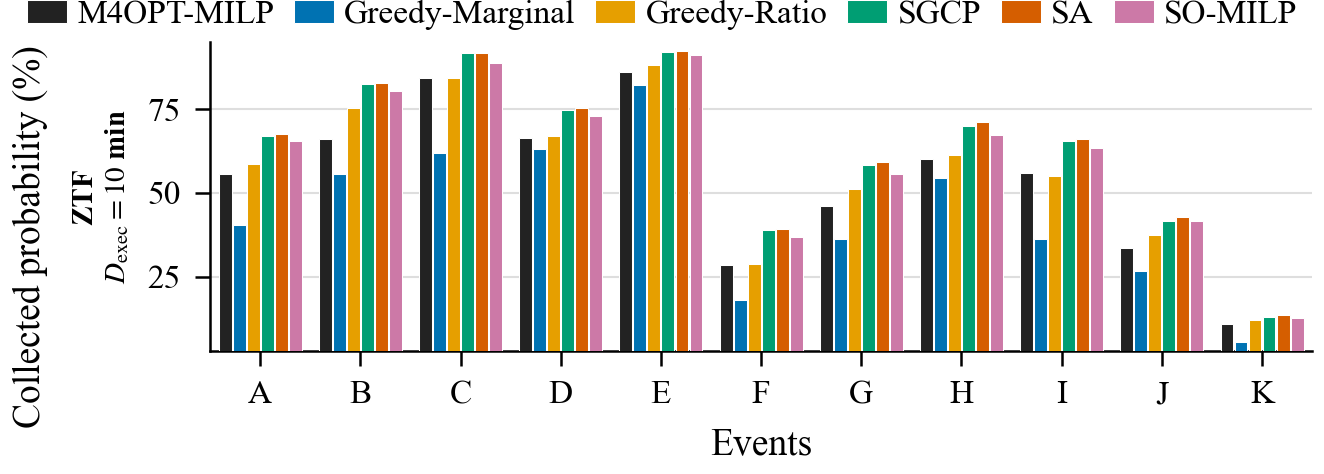

Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp1_p2_probability_percent.png


**exp1_p2_probability_percent**

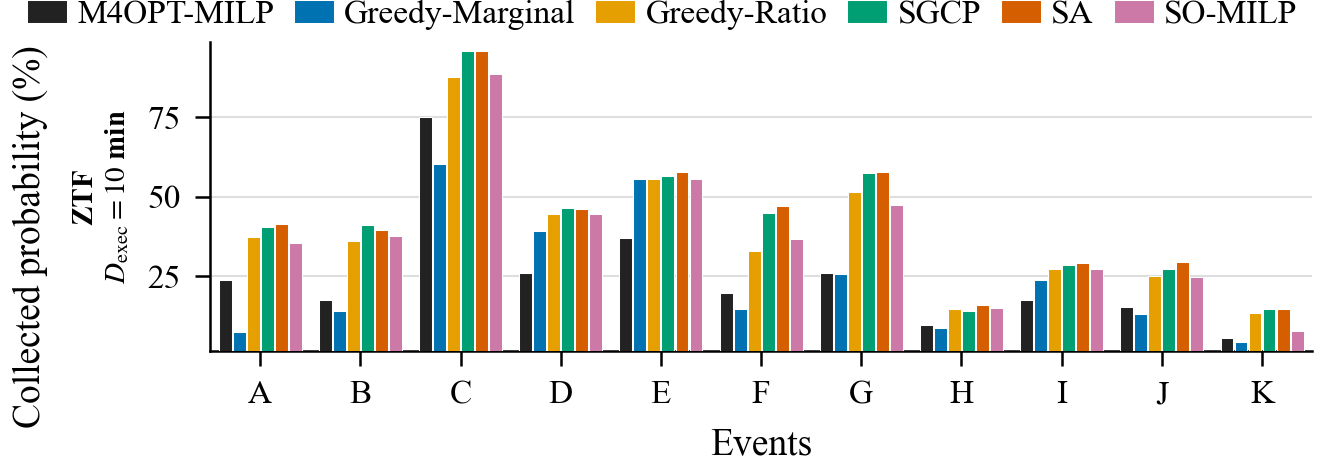

In [4]:
run_plot('exp1_probability')

### Planning time by event

Planning-time lines.

In [5]:
PLOT_CONFIG['exp1_time'] = {
    # Select data for this plot.
    'missions': ['ztf'], # all missions: ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],

    # Format for this plot.
    # 'figsize': (3.68, 4.3), 
    'figsize': (3.68, 1.5), 
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'event_label_mode': 'index',  # "index" or "names".
    'event_rotation': 45,
    'auto_height': False,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp1_{problem}_{metric}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp1_p1_planning_time_seconds.png


**exp1_p1_planning_time_seconds**

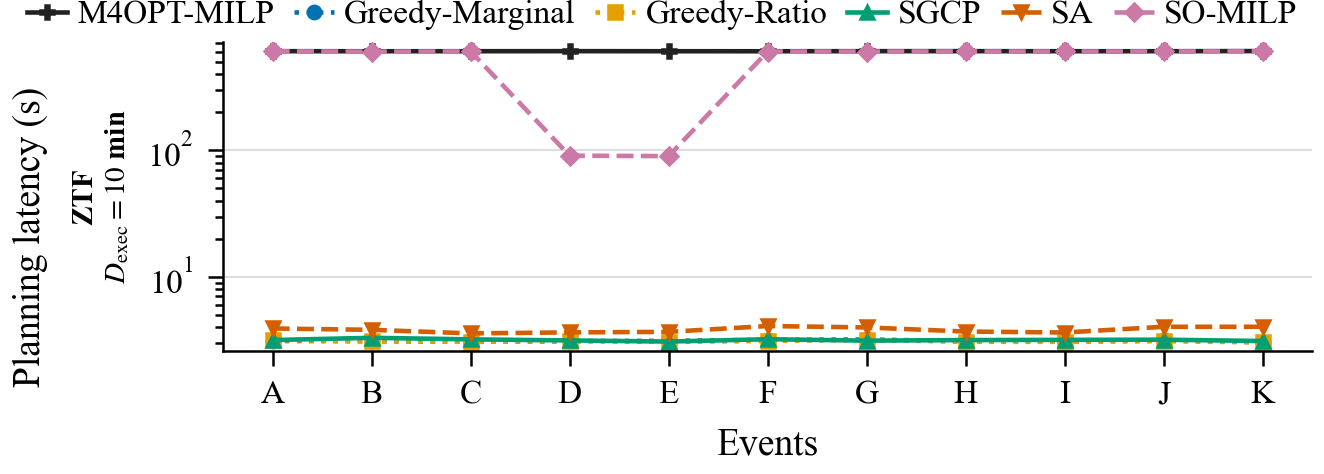

Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp1_p2_planning_time_seconds.png


**exp1_p2_planning_time_seconds**

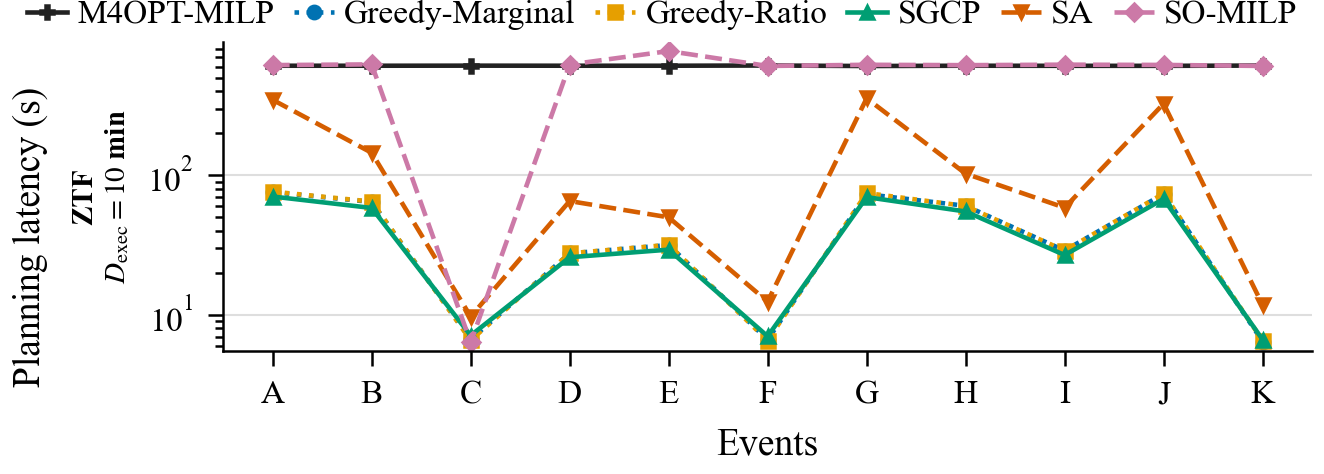

In [6]:
run_plot('exp1_time')

## Experiment 2 — deadline comparisons

Evaluate the four heuristics on 37 LIGO localization maps using M4OPT’s ZTF configuration, under P1 and P2, with observation budgets of 5, 10, 20, and 30 minutes. All methods retain pixels within the 99% localization region. Include SO-MILP with a 2-hour solver time limit. Report collected probability, planning time.

### Probability at a selected deadline

In [7]:
PLOT_CONFIG['exp2_events_probability'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],
    'deadline_minutes': 10,

    # Format for this plot.
    'figsize': (3.58, 2.8),  # Width, height in inches.
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'event_label_mode': 'index',  # "index" or "names".
    'event_rotation': 45,
    'auto_height': False,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp2_{mission}_budget{deadline:g}min_{metric}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp2_ztf_budget10min_probability_percent.png


**exp2_ztf_budget10min_probability_percent**

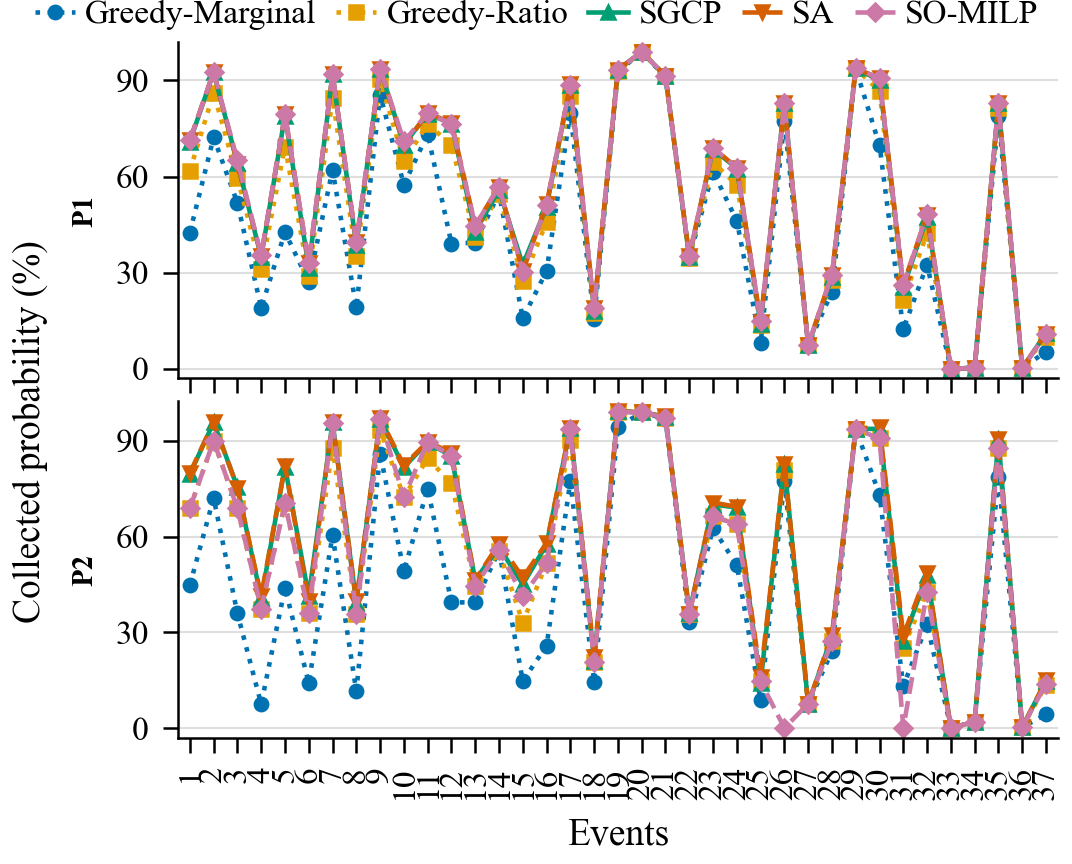

In [8]:
run_plot('exp2_events_probability')

### Planning time at a selected deadline

In [9]:
PLOT_CONFIG['exp2_events_time'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],
    'deadline_minutes': 10,

    # Format for this plot.
    'figsize': (3.58, 2.8),  # Width, height in inches.
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'event_label_mode': 'index',  # "index" or "names".
    'event_rotation': 45,
    'auto_height': False,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp2_{mission}_budget{deadline:g}min_{metric}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp2_ztf_budget10min_planning_time_seconds.png


**exp2_ztf_budget10min_planning_time_seconds**

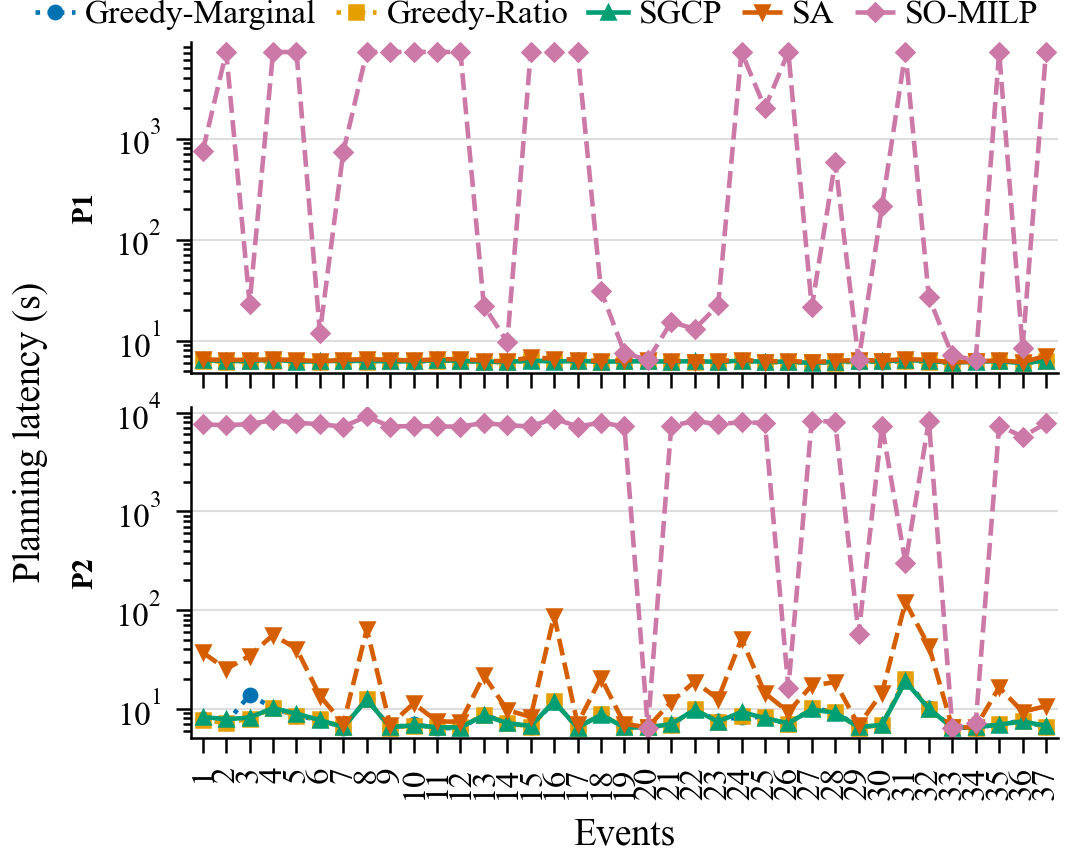

In [10]:
run_plot('exp2_events_time')

### Mean probability versus deadline

Mean across event means, with pointwise 95% confidence intervals.

In [11]:
PLOT_CONFIG['exp2_mean_probability'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing',
    ],

    # Format for this plot.
    'figsize': (3.58, 2.8),  # Width, height in inches.
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp2_mean_{metric}_vs_deadline_{mission}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp2_mean_probability_percent_vs_deadline_ztf.png


**exp2_mean_probability_percent_vs_deadline_ztf**

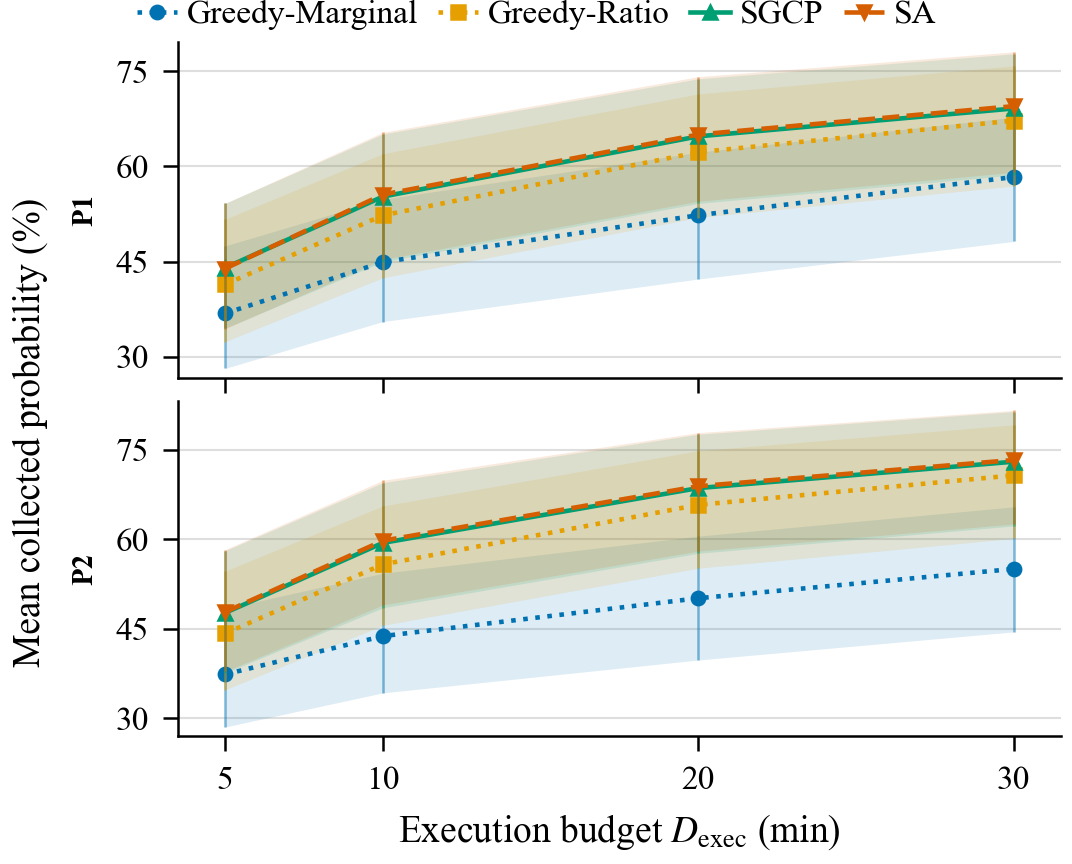

In [12]:
run_plot('exp2_mean_probability')

### Mean planning time versus deadline

Mean planning latency across event means, with pointwise 95% confidence intervals.

In [13]:
PLOT_CONFIG['exp2_mean_time'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing',
    ],

    # Format for this plot.
    'figsize': (3.58, 2.8),  # Width, height in inches.
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'panel_fontsize': 7,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp2_mean_{metric}_vs_deadline_{mission}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp2_mean_planning_time_seconds_vs_deadline_ztf.png


**exp2_mean_planning_time_seconds_vs_deadline_ztf**

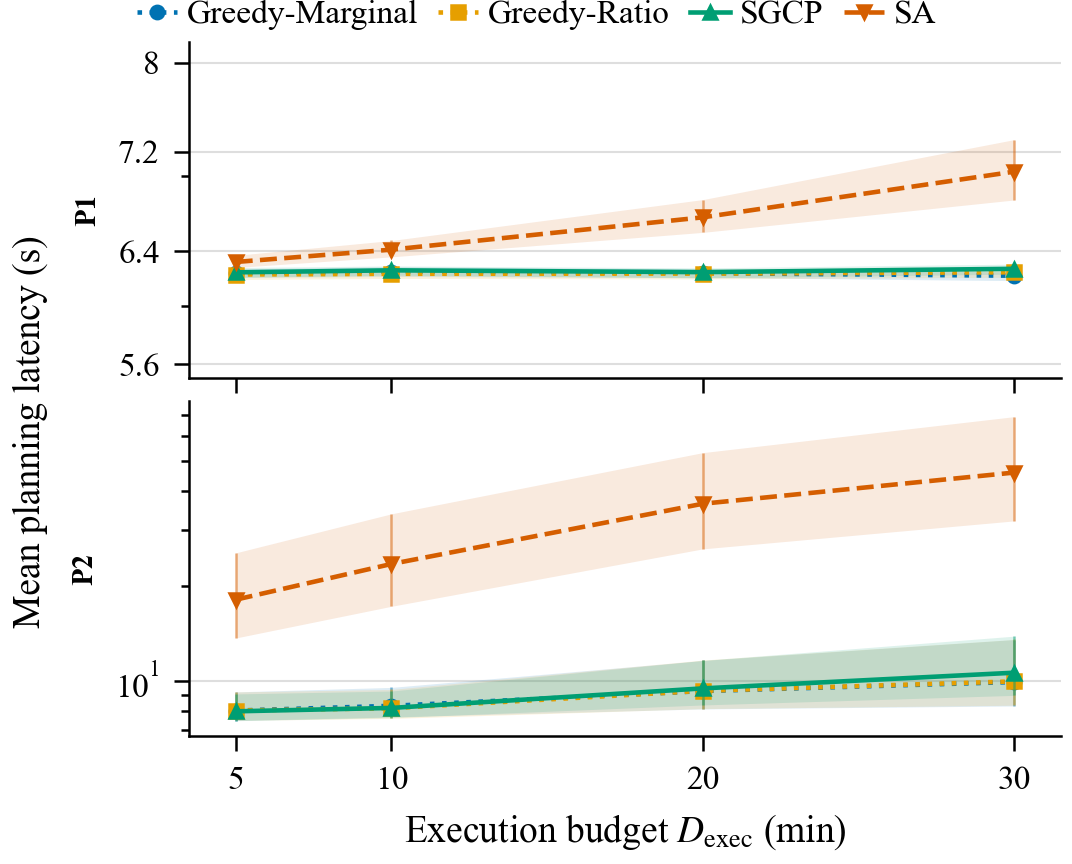

In [14]:
run_plot('exp2_mean_time')

## Experiment 3 — Compare P1/P2

Compare P1 and P2 on 37 LIGO localization maps using M4OPT’s ZTF configuration and GCP, with the same candidate tiles, initial pointing, exposure bounds, and observation budgets. P1 fixes each tile’s exposure to its largest pixel requirement, respecting the minimum exposure. P2 selects exposures and counts only pixels whose requirements are met. Report paired differences in collected probability and planning time.

Compute WCET across all original events and runs at each deadline.


### Mean planning time with 95% CI: P1 versus P2

In [15]:
PLOT_CONFIG['exp3_time'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': ['gcp'],  # None = all algorithms found.

    # Format for this plot.
    'figsize': (3.58, 1.5),
    'fit_legend': True,
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp3_mean_{metric}_vs_deadline_{mission}_{algorithm}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp3_mean_planning_time_seconds_vs_deadline_ztf_gcp.png


**exp3_mean_planning_time_seconds_vs_deadline_ztf_gcp**

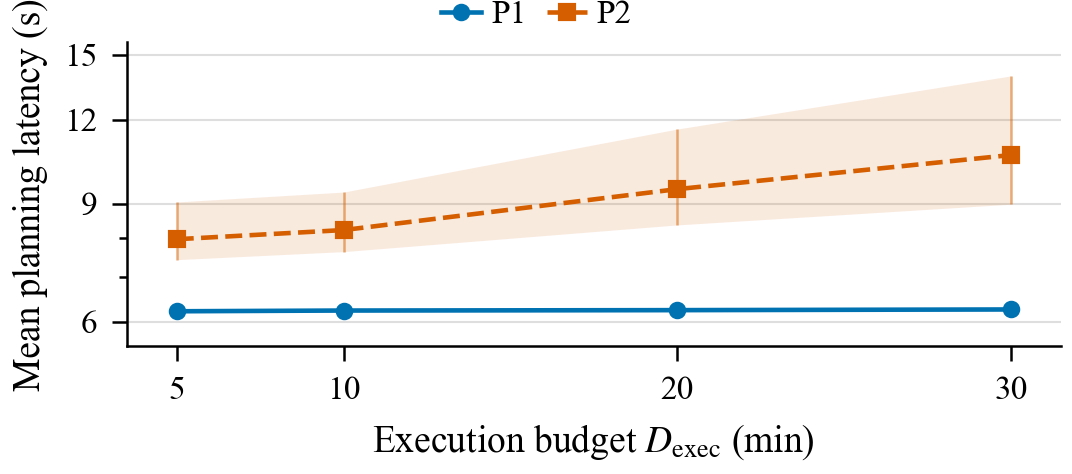

In [16]:
run_plot('exp3_time')

### Mean probability: P1 versus P2

In [17]:
PLOT_CONFIG['exp3_probability'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': ['gcp'],  # None = all algorithms found.

    # Format for this plot.
    'figsize': (3.58, 1.5), 
    'fit_legend': True,
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp3_mean_{metric}_vs_deadline_{mission}_{algorithm}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp3_mean_probability_percent_vs_deadline_ztf_gcp.png


**exp3_mean_probability_percent_vs_deadline_ztf_gcp**

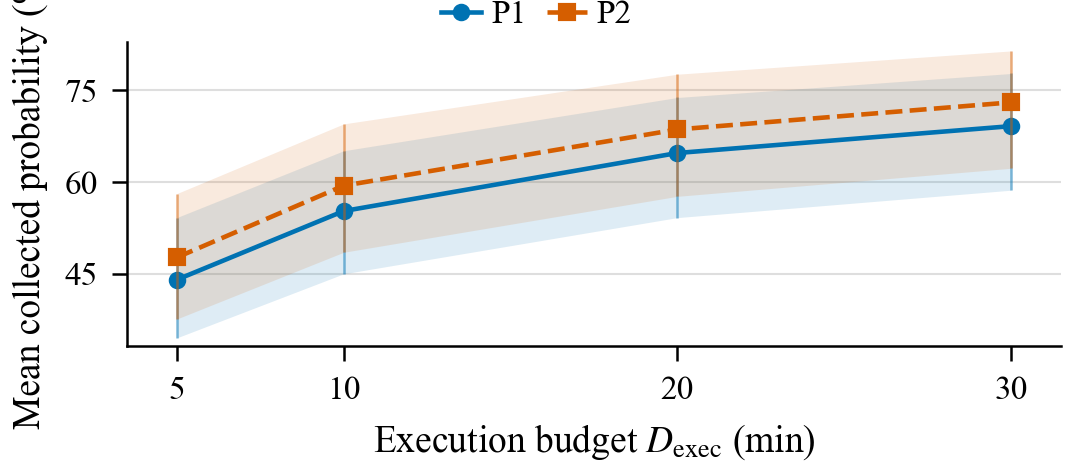

In [18]:
run_plot('exp3_probability')

### Probability after deducting WCET: P1 versus P2

Uses actual reruns with $D_{\mathrm{adjusted}} = D - \mathrm{WCET}$. The x-axis remains the original response deadline $D$. 

In [19]:
PLOT_CONFIG['exp3_adjusted_probability'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': ['gcp'],  # None = all algorithms found.

    # Format for this plot.
    'figsize': (3.58, 1.5),  # Width, height in inches.
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp3_adjusted_mean_{metric}_vs_deadline_{mission}_{algorithm}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp3_adjusted_mean_probability_percent_vs_deadline_ztf_gcp.png


**exp3_adjusted_mean_probability_percent_vs_deadline_ztf_gcp**

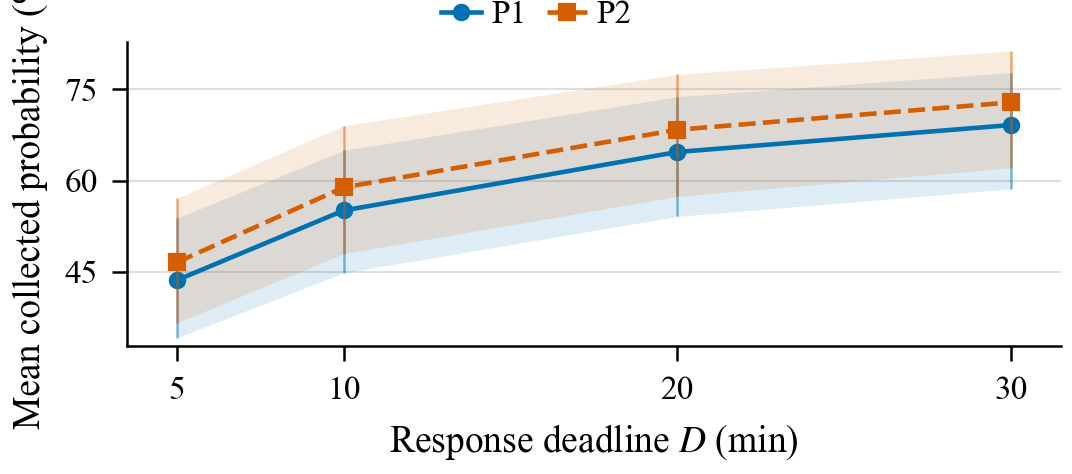

In [20]:
run_plot('exp3_adjusted_probability')

### Combined planning time and adjusted probability

One figure per mission/algorithm, with **(a)** original mean planning latency and
**(b)** mean collected probability from the actual WCET-adjusted reruns.
Both panels use the existing event pairing and pointwise 95% bootstrap CIs.
They share x limits and tick locations, aligned plot boundaries, and one P1/P2 legend.
The x-axis labels retain their respective meanings: original execution budget
in (a), original response deadline in (b).

Set `ROOT_FOLDER` and run **Shared setup**, then the two cells below.
The combined plot has its own configuration; running the standalone plots is unnecessary.
`figsize` is the total width and height in inches. With `fit_legend=False` and
`bbox_inches=None`, the saved PDF retains exactly that size. PNG and PDF files
are written to `ROOT_FOLDER / "plots"`.


In [ ]:
PLOT_CONFIG['exp3_combined'] = {
    # Select data for both panels.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],
    'algorithms': ['gcp'],  # None = all algorithms found.

    # Total canvas size for the pair, suitable for one paper column.
    'figsize': (3.58, 1.85),
    'fit_legend': False,
    'bbox_inches': None,  # Preserve the configured size; do not crop on export.
    'label_fontsize': 8,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'panel_fontsize': 9,
    'legend_gap': 0.02,
    'show_title': False,
    'ylim': None,
    'time_ylim': None,  # Independent y limits; None = automatic.
    'probability_ylim': None,
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Wrapped labels fit the narrow panels without shrinking the text.
    'time_xlabel': 'Deadline ' + r'$D_{\mathrm{exec}}$',
    'probability_xlabel': 'Deadline ' + r'$D$',
    'time_ylabel': 'Mean planning latency (s)',
    'probability_ylabel': 'Mean collected probability (%)',

    'save_pdf': True,
    'dpi': 300,
    'filename': 'exp3_time_and_adjusted_probability_{mission}_{algorithm}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp3_time_and_adjusted_probability_ztf_gcp.png
Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp3_time_and_adjusted_probability_ztf_gcp.pdf


**exp3_time_and_adjusted_probability_ztf_gcp**

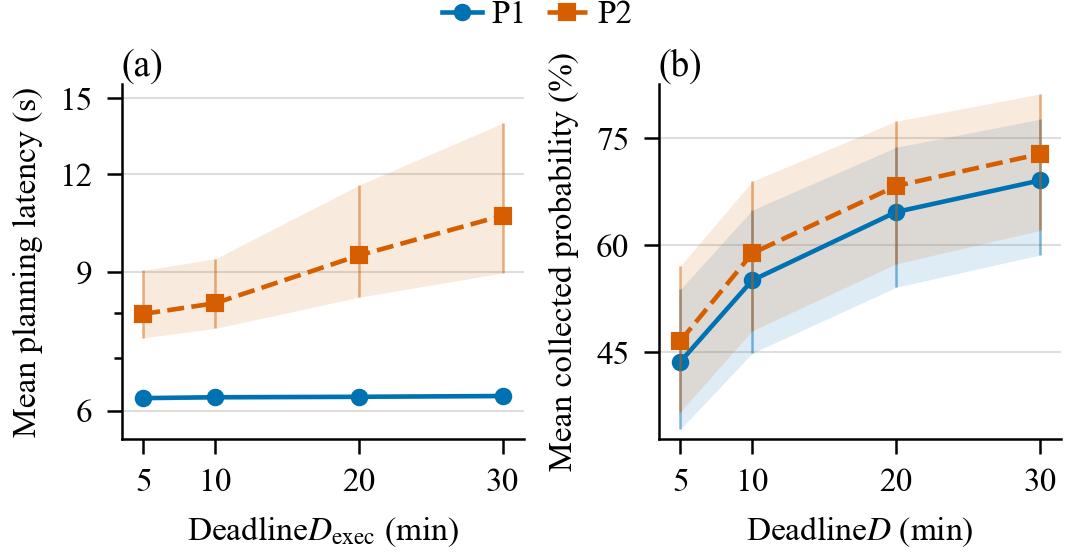

In [32]:
run_plot('exp3_combined')


## Experiment 4 — Compare all Heuristics under WCET adjusted deadline

Evaluate the four heuristics on 37 LIGO localization maps using M4OPT’s ZTF configuration, under P2, with a fixed response deadline covering planning and observation. For each planner and map, perform 10 calibration runs at each observation budget of 5, 10, 20, and 30 minutes, and use the maximum planning time across these runs and cross all maps as WCET. In separate evaluation runs, compare the original observation budget with a budget reduced by WCET. Count only probability from observations completed before the response deadline, and report deadline misses and planning-time overruns.

### Observed WCET versus deadline

In [23]:
PLOT_CONFIG['exp4_wcet'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': ['greedy_marginal', 'greedy_ratio', 'gcp', 'simulated_annealing'],

    # Format for this plot.
    'figsize': (3.58, 1.5), 
    'fit_legend': True,  # False keeps the configured canvas width.
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp4_wcet_vs_deadline_{metric}_{problem}_{mission}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp4_wcet_vs_deadline_planning_time_seconds_p2_ztf.png


**exp4_wcet_vs_deadline_planning_time_seconds_p2_ztf**

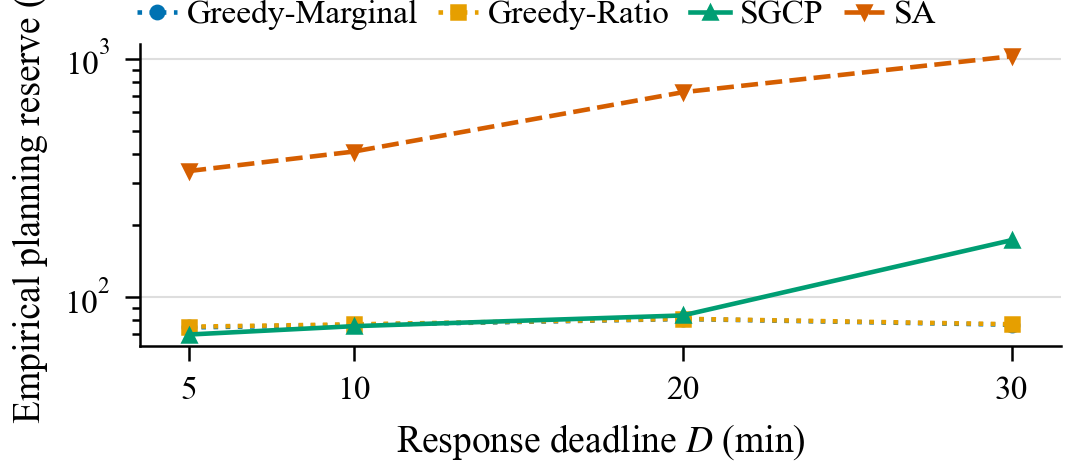

In [24]:
run_plot('exp4_wcet')

### Mean adjusted probability versus deadline

In [25]:
PLOT_CONFIG['exp4_probability'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],

    # Format for this plot.
    'figsize': (3.58, 1.5),  # Width, height in inches.
    'fit_legend': True, 
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp4_mean_{metric}_vs_deadline_{problem}_{mission}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp4_mean_probability_percent_vs_deadline_p2_ztf.png


**exp4_mean_probability_percent_vs_deadline_p2_ztf**

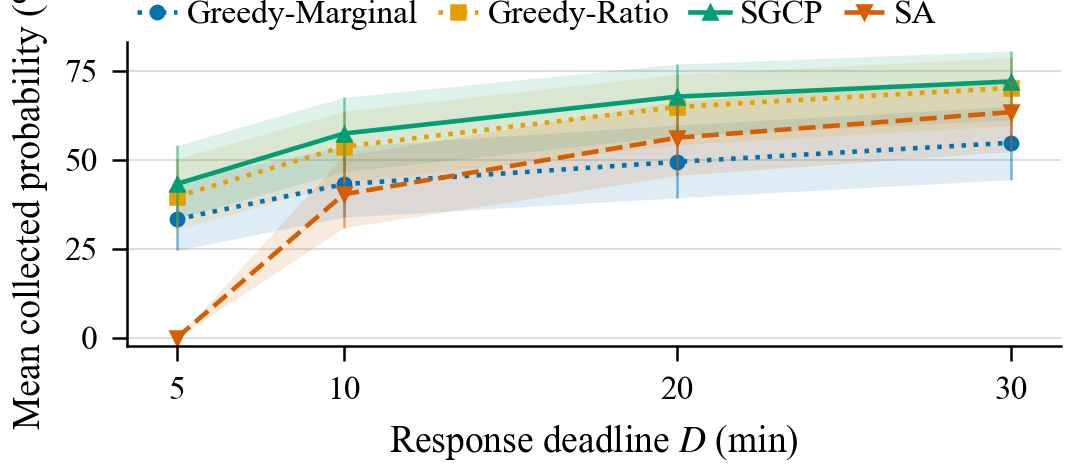

In [26]:
run_plot('exp4_probability')

### Combined empirical planning reserve and adjusted probability

One figure per selected formulation and mission: **(a)** empirical planning
reserve from the original runs and **(b)** mean collected probability from
the adjusted reruns. Both panels have aligned x-axes, single-line y-axis labels,
and a shared two-row legend. Probability bands are pointwise 95% bootstrap CIs.

Run **Shared setup**, the `exp4_wcet` and `exp4_probability` configuration
cells above, then the three cells below. The data selections are inherited
separately from those two configurations, so the WCET panel retains its four
algorithms and the probability panel retains its six. The standalone plot
execution cells do not need to be run.

The plotting helpers are embedded in the first cell below. `figsize` gives
the total canvas size; PNG and PDF files are saved to `ROOT_FOLDER / "plots"`.


In [ ]:
# Helpers for the combined Experiment 4 figure.
# All code is embedded here; no external Python file is needed.
from contextlib import contextmanager as _exp4_contextmanager
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np


_EXP4_COMBINED_DEFAULTS = {
    'figsize': (3.58, 2.0),
    'label_fontsize': 8,
    'tick_fontsize': 8,
    'legend_fontsize': 7,
    'legend_ncol': 3,
    'panel_fontsize': 9,
    'legend_gap': 0.02,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,
    'y_padding': 0.03,
    'wcet_ylim': None,
    'probability_ylim': None,
    'xlabel': r'Deadline $D$ (min)',
    'wcet_ylabel': None,  # Use the selected timing metric's label.
    'probability_ylabel': 'Mean collected probability (%)',
    'show_title': False,
    'save_pdf': True,
    'dpi': 300,
    'filename': 'exp4_wcet_and_probability_{problem}_{mission}',
}


@_exp4_contextmanager
def _exp4_combined_analysis_settings(options):
    """Honor the source plot's scientific settings and restore them afterwards."""
    changes = {
        'BOOTSTRAP_SAMPLES': options['bootstrap_samples'],
        'RANDOM_SEED': options['random_seed'],
        'REQUIRE_ALL_EVENTS': options['require_all_events'],
        'FAILED_RUN_PROBABILITY': options['failed_run_probability'],
    }
    previous = {key: globals()[key] for key in changes}
    globals().update(changes)
    try:
        yield
    finally:
        globals().update(previous)


def _exp4_combined_options(plot_id, style, mission=None, problem=None):
    options = get_plot_options(plot_id, mission=mission, problem=problem)
    if mission is not None:
        options.update(options.get('figure_overrides', {}).get((mission, problem), {}))
    for key in ('label_fontsize', 'tick_fontsize', 'panel_fontsize', 'linewidth',
                'markersize', 'band_alpha', 'y_padding'):
        options[key] = style[key]
    limit_key = 'wcet_ylim' if plot_id == 'exp4_wcet' else 'probability_ylim'
    if style[limit_key] is not None:
        options['ylim'] = style[limit_key]
    return options


def _exp4_combined_select(rows, options, mission, problem):
    algorithms = list(LABELS) if options['algorithms'] is None else options['algorithms']
    if (not options['enabled'] or mission not in options['missions']
            or problem not in options['problems']):
        return [], algorithms
    selected = [r for r in rows if r['mission'] == mission and r['problem'] == problem
                and r['algorithm'] in algorithms]
    return selected, algorithms


def _exp4_combined_draw_wcet(ax, rows, algorithms, mission, options):
    """Same maximum over valid calibration runs as plot_wcet."""
    metric = options['metric']
    if not metric.endswith('_seconds'):
        raise ValueError('exp4_wcet must use a time metric')
    deadlines = sorted({r['comparison_deadline_seconds'] for r in rows})
    x = np.asarray(deadlines) / 60
    plotted_values = []
    for algorithm in algorithms:
        selected_algorithm = [r for r in rows if r['algorithm'] == algorithm]
        maximum = [max((r[metric] for r in selected_algorithm
                        if r['comparison_deadline_seconds'] == deadline
                        and math.isfinite(r[metric]) and r[metric] >= 0), default=math.nan)
                   for deadline in deadlines]
        if any(math.isfinite(value) for value in maximum):
            ax.plot(x, maximum, label=LABELS[algorithm],
                    **dict(STYLES[algorithm], linewidth=options['linewidth'],
                           markersize=options['markersize']))
            plotted_values.extend(maximum)
    format_axis(ax, plotted_values, metric, 'exp4', mission, options)


def _exp4_combined_draw_probability(ax, rows, algorithms, mission, options):
    """Same event means, completeness rule and bootstrap CIs as plot_means."""
    metric = options['metric']
    if metric != 'probability_percent':
        raise ValueError('exp4_probability must use probability_percent')
    expected_events = {r['map'] for r in rows}
    deadlines = sorted({r['comparison_deadline_seconds'] for r in rows})
    x = np.asarray(deadlines) / 60
    definitions = sorted({(r['problem'], r['algorithm'], r['max_fields']) for r in rows},
                         key=lambda item: (algorithms.index(item[1]), item[2]))
    plotted_values = []
    for problem, algorithm, cap in definitions:
        means, lows, highs, counts = [], [], [], []
        for deadline in deadlines:
            selected = [r for r in rows if (r['problem'], r['algorithm'], r['max_fields'],
                        r['comparison_deadline_seconds']) == (problem, algorithm, cap, deadline)]
            values = metric_values(selected, metric)
            event_means = [np.mean(values[event]) for event in sorted(values)]
            mean, low, high = mean_ci(event_means)
            count = len(values)
            complete = count == len(expected_events)
            plotted = count > 0 and (complete or not REQUIRE_ALL_EVENTS)
            means.append(mean if plotted else math.nan)
            lows.append(low if plotted else math.nan)
            highs.append(high if plotted else math.nan)
            counts.append(count)
            if not complete:
                print(f'exp4_combined/{mission}/{problem}/{algorithm}: '
                      f'{deadline / 60:g} min: {count}/{len(expected_events)} maps; '
                      + ('partial mean plotted' if plotted else 'point omitted'))
        if not any(math.isfinite(value) for value in means):
            continue
        label = LABELS[algorithm]
        if len({r['max_fields'] for r in rows if r['algorithm'] == algorithm}) > 1:
            label += f' (n={cap})'
        style = dict(STYLES[algorithm], linewidth=options['linewidth'],
                     markersize=options['markersize'])
        ax.fill_between(x, lows, highs, color=style['color'], alpha=options['band_alpha'], linewidth=0)
        ax.plot(x, means, **style, label=label)
        valid_ci = np.isfinite(lows) & np.isfinite(highs)
        ax.vlines(x[valid_ci], np.asarray(lows)[valid_ci], np.asarray(highs)[valid_ci],
                  color=style['color'], linewidth=0.6, alpha=0.5)
        plotted_values.extend(means + lows + highs)
        for position, value, count in zip(x, means, counts):
            if math.isfinite(value) and count < len(expected_events):
                ax.annotate(f'{count}/{len(expected_events)}', (position, value), xytext=(3, 4),
                            textcoords='offset points', color=style['color'],
                            fontsize=options['panel_fontsize'])
    format_axis(ax, plotted_values, metric, 'exp4', mission, options)


def run_exp4_combined():
    """Export one aligned WCET/probability figure per selected problem and mission."""
    required = ('ROOT_FOLDER', 'PLOT_CONFIG', 'get_plot_options', 'load_results',
                'metric_values', 'mean_ci', 'format_axis', 'LABELS', 'STYLES')
    missing = [key for key in required if key not in globals()]
    if missing:
        raise RuntimeError('Run Shared setup first. '
                           f'Missing: {missing}')
    if not {'exp4_wcet', 'exp4_probability'} <= PLOT_CONFIG.keys():
        raise RuntimeError('Run both exp4_wcet and exp4_probability configuration cells first.')
    style = {**_EXP4_COMBINED_DEFAULTS, **PLOT_CONFIG.get('exp4_combined', {})}
    if len(style['figsize']) != 2 or not all(math.isfinite(v) and v > 0 for v in style['figsize']):
        raise ValueError('figsize must contain two positive numbers in inches')
    if not isinstance(style['legend_ncol'], int) or style['legend_ncol'] < 1:
        raise ValueError('legend_ncol must be a positive integer')

    sources = {}
    for plot_id, stage in [('exp4_wcet', 'original'), ('exp4_probability', 'final')]:
        options = _exp4_combined_options(plot_id, style)
        folder = Path(ROOT_FOLDER) / options['experiment'] / options['input_folder']
        if not options['enabled']:
            print(f'{plot_id}: disabled; combined plot skipped')
            return []
        if not folder.is_dir():
            print(f'{plot_id}: no input folder at {folder}; check ROOT_FOLDER')
            return []
        sources[plot_id] = [dict(row, stage=stage) for row in
                            load_results(folder, options['result_pattern'], allow_empty=True)]
        if not sources[plot_id]:
            print(f'{plot_id}: no readable results; combined plot skipped')
            return []

    keys = sorted({(r['problem'], r['mission']) for rows in sources.values() for r in rows})
    written = []
    used_names = set()
    for problem, mission in keys:
        wcet_options = _exp4_combined_options('exp4_wcet', style, mission, problem)
        prob_options = _exp4_combined_options('exp4_probability', style, mission, problem)
        wcet_rows, wcet_algorithms = _exp4_combined_select(
            sources['exp4_wcet'], wcet_options, mission, problem)
        prob_rows, prob_algorithms = _exp4_combined_select(
            sources['exp4_probability'], prob_options, mission, problem)
        if not wcet_rows or not prob_rows:
            continue
        fig, axes = plt.subplots(1, 2, sharex=True, figsize=style['figsize'], layout='constrained')
        fig.get_layout_engine().set(h_pad=style['legend_gap'])
        try:
            with _exp4_combined_analysis_settings(wcet_options):
                _exp4_combined_draw_wcet(axes[0], wcet_rows, wcet_algorithms, mission, wcet_options)
            with _exp4_combined_analysis_settings(prob_options):
                _exp4_combined_draw_probability(axes[1], prob_rows, prob_algorithms, mission, prob_options)
            metric_labels = {'planning_time_seconds': 'Empirical planning reserve (s)',
                             'solver_call_time_seconds': 'Observed solver-call WCET (s)',
                             'solution_time_seconds': 'Observed solution-time WCET (s)'}
            axes[0].set_ylabel(style['wcet_ylabel'] or metric_labels.get(wcet_options['metric'],
                                   'Observed WCET (s)'), fontsize=style['label_fontsize'])
            axes[1].set_ylabel(style['probability_ylabel'], fontsize=style['label_fontsize'])
            deadlines = sorted({r['comparison_deadline_seconds'] for r in wcet_rows + prob_rows})
            axes[0].set_xticks(np.asarray(deadlines) / 60, [f'{d / 60:g}' for d in deadlines])
            for ax, tag in zip(axes, ['(a)', '(b)']):
                ax.set_xlabel(style['xlabel'], fontsize=style['label_fontsize'])
                ax.set_title(tag, loc='left', fontsize=style['panel_fontsize'], pad=1.5)
            fig.align_xlabels(axes)
            if style['show_title']:
                fig.suptitle(f'{problem.upper()} / {mission.upper()}', fontsize=style['label_fontsize'])

            # Probability first gives the six-entry legend its configured order.
            legend = {}
            for ax in [axes[1], axes[0]]:
                handles, labels = ax.get_legend_handles_labels()
                for handle, label in zip(handles, labels):
                    legend.setdefault(label, handle)
            if not legend:
                continue
            fig.legend(legend.values(), legend.keys(), loc='outside upper center',
                       ncol=min(style['legend_ncol'], len(legend)), frameon=False,
                       fontsize=style['legend_fontsize'], columnspacing=0.6,
                       handlelength=1.2, handletextpad=0.3, borderpad=0, borderaxespad=0)
            name = style['filename'].format(problem=problem, mission=mission)
            output = Path(ROOT_FOLDER) / 'plots' / Path(name).name
            if output in used_names:
                raise ValueError('Duplicate combined filename; include {problem} and {mission}.')
            used_names.add(output)
            output.parent.mkdir(parents=True, exist_ok=True)
            with plt.rc_context({'savefig.bbox': None}):
                for extension in (['png', 'pdf'] if style['save_pdf'] else ['png']):
                    path = Path(f'{output}.{extension}')
                    fig.savefig(path, dpi=style['dpi'], bbox_inches=None)
                    written.append(path)
                    print(f'Wrote {path}')
            if globals().get('DISPLAY_PLOTS', True):
                from IPython.display import Image, Markdown, display
                display(Markdown(f'**{output.name}**'))
                display(Image(filename=f'{output}.png'))
        finally:
            plt.close(fig)
    if not written:
        print('exp4_combined: no selected mission/problem has data for both panels')
    return written

In [ ]:
PLOT_CONFIG['exp4_combined'] = {
    # Data selections come from exp4_wcet and exp4_probability above.

    # Total canvas size for both panels and the two-row legend.
    'figsize': (3.58, 2.0),
    'label_fontsize': 8,
    'tick_fontsize': 8,
    'legend_fontsize': 7,
    'legend_ncol': 3,
    'panel_fontsize': 9,
    'legend_gap': 0.02,
    'show_title': False,
    'wcet_ylim': None,  # Use the corresponding source plot's y limits.
    'probability_ylim': None,
    'y_padding': 0.03,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Both x-axes show the original response deadline, in minutes.
    'xlabel': r'Deadline $D$ (min)',
    'wcet_ylabel': 'Empirical planning reserve (s)',
    'probability_ylabel': 'Mean collected probability (%)',

    # Preserve the configured canvas size when exporting.
    'save_pdf': True,
    'dpi': 300,
    'filename': 'exp4_wcet_and_probability_{problem}_{mission}',
}


In [ ]:
_ = run_exp4_combined()


### Mean adjusted planning time versus deadline

In [27]:
PLOT_CONFIG['exp4_time'] = {
    # Select data for this plot.
    'missions': ['uvex', 'ultrasat', 'ztf', 'rubin'],
    'problems': ['p1', 'p2'],  # ['p1'], ['p2'], or both.
    'algorithms': [
        'm4opt_milp', 'greedy_marginal', 'greedy_ratio',
        'gcp', 'simulated_annealing', 'ilp_continuous',
    ],

    # Format for this plot.
    'figsize': (3.58, 1.5),  
    'fit_legend': True,  
    'label_fontsize': 9,
    'tick_fontsize': 8,
    'legend_fontsize': 8,
    'legend_gap': 0.0,
    'show_title': False,
    'ylim': None,  # None = automatic.
    'y_padding': 0.03,
    'log_time': True,
    'linewidth': 1.1,
    'markersize': 3.2,
    'band_alpha': 0.13,

    # Output.
    'save_pdf': False,
    'dpi': 300,
    'filename': 'exp4_mean_{metric}_vs_deadline_{problem}_{mission}',
}


Wrote /Users/filip/Documents/Projects-MPI-SWS/RTAS 2027/Telescope-Searching-Overlap-Tiling/results/plots/exp4_mean_planning_time_seconds_vs_deadline_p2_ztf.png


**exp4_mean_planning_time_seconds_vs_deadline_p2_ztf**

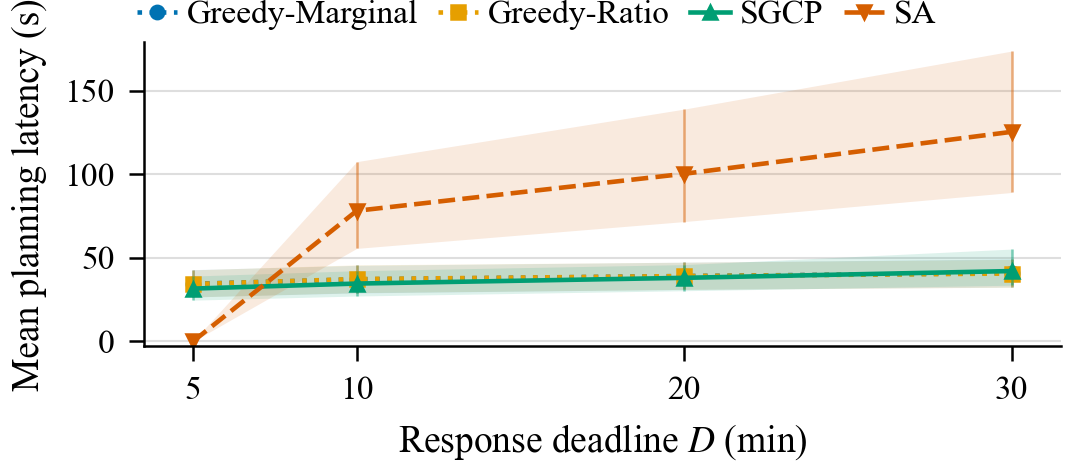

In [28]:
run_plot('exp4_time')